# 보행망과 직선거리 모델의 동일 지역 예측 비교

2024년 4분기 같은 시간과 같은 대여소 집합에서 3가지 구획의 가중치를 복원한다. 대여소를 분할하거나 수요 비중으로 예측을 배분하지 않고, 각 구획의 예측을 통째로 더할 수 있는 가장 세밀한 공통 구역을 만든다. 구획을 가로지르는 모든 합병을 허용하기 때문에 일부 구역이 커질 수 있다. 공통 구역 오차의 단위는 구역 한 곳·한 시간당 대여 건수다. 4분기는 앞선 실험에도 사용된 회고 평가 기간이다. 먼저 보행망 군집·학습 노트북을 실행한다.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import torch
from IPython.display import display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "전처리/walking_forecast.py").is_file())
OUT = ROOT / "모델"
SITE = ROOT / "따릉이 대여소 비교"
sys.path.insert(0,str(ROOT/"전처리"))
from walking_forecast import (hours, count_departures, prepare_inputs, ClusterNet, VARIANTS,
                              DEVICE, BATCH, EPOCHS, SEED)
stations = pd.read_csv(SITE/"보행망 군집 배정.csv").set_index("대여소번호").sort_index()
assert len(stations)==stations.index.nunique()==2766

## 세 구획을 모두 포함하는 공통 구역

In [2]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
import gc

straight = pd.read_csv(SITE/"서울 전체 직선거리 500m 군집 배정.csv")
straight = straight.loc[straight["기준월"]=="2024-12"].set_index("대여소번호")
parts = pd.DataFrame({
    "직선 500m": straight["완전연결 군집번호"].reindex(stations.index),
    "직선 600m": stations["직선 600m 군집번호"],
    "보행망 선택": stations["보행망 군집번호"],
})
assert parts.notna().all().all()
nodes = np.arange(len(parts))
edges = np.concatenate([parts.index.get_indexer(parts[col]) for col in parts])
assert (edges >= 0).all()
adj = coo_matrix((np.ones(len(edges)), (np.tile(nodes,len(parts.columns)),edges)),
                 shape=(len(nodes),len(nodes))).tocsr()
n_zones, component = connected_components(adj,directed=False)
zones = pd.Series(component,index=parts.index)
zones = zones.groupby(zones).transform(lambda s:s.index.min())
zone_ids = pd.Index(sorted(zones.unique()))
for key in parts:
    assert zones.groupby(parts[key]).nunique().eq(1).all()
zone_sizes = zones.value_counts()
print(f"공통 구역 {n_zones:,}개, 대여소 수 중앙값 {zone_sizes.median():g}개, 최대 {zone_sizes.max()}개")
parts.assign(공통구역=zones).to_csv(SITE/"보행망 직선거리 공통 평가구역.csv", encoding="utf-8-sig")

공통 구역 632개, 대여소 수 중앙값 3개, 최대 23개


## 저장된 4분기 모델을 복원해 같은 정답으로 평가

24개 조합 모두 기존 구획에서 기록한 MAE와 RMSE를 재현한 후 공통 구역으로 합산한다. 대여량 정답과 전주 동일 시각 기준선도 모든 구획에서 구역·시간별로 정확히 일치해야 한다.

In [3]:
suffix = {"base":"","both":"_returns_weather","returns_only":"_returns_only","weather_match_only":"_weather_match_only"}
def checkpoint_name(part,kind,variant):
    if part == "직선 500m":
        return f"cluster1021_{kind.lower()}{suffix[variant]}.pt"
    prefix = "silhouette" if part == "직선 600m" else "walking"
    return f"{prefix}_{kind.lower()}_{variant}.pt"

sources = {"직선 500m":"1021개 군집 피처 개별 비교.csv","직선 600m":"실루엣 군집 피처별 성능.csv",
           "보행망 선택":"보행망 군집 피처별 성능.csv"}
def score(pred, truth):
    residual = pred.astype("float64") - truth
    return np.abs(residual).mean(), np.sqrt(np.square(residual).mean())

def combine(values, parents):
    out = np.zeros((len(values), n_zones), dtype=np.result_type(values.dtype,"float64"))
    np.add.at(out.T, parents, values.T)
    return out

def evaluate_partition(name):
    group = parts[name]
    ids = pd.Index(sorted(group.unique()))
    parents = zone_ids.get_indexer(zones.groupby(group).first().loc[ids])
    assert (parents>=0).all()
    totals, late_returns, confirmed = count_departures(group)
    context_at, inputs, _, _, _ = prepare_inputs(group,totals,late_returns,confirmed)
    start = hours.get_loc(pd.Timestamp("2024-10-01 00:00"))
    target = totals[start:]
    common_target = combine(target,parents)
    np.testing.assert_array_equal(common_target.sum(axis=1),target.sum(axis=1))
    reference = pd.read_csv(OUT/sources[name]).query("분기 == 4").set_index(["모델","추가 입력"])
    context,scaling = context_at(start)
    n = len(ids)
    rows = []
    for variant,(label,features) in VARIANTS.items():
        for kind in ("MLP","GRU"):
            ck = torch.load(OUT/checkpoint_name(name,kind,variant),map_location="cpu",weights_only=True)
            assert ck["cluster_ids"] == ids.tolist() and pd.Timestamp(ck["cutoff"]) == hours[start]
            for key in scaling:
                np.testing.assert_allclose(scaling[key],ck["scaling"][key])
            net = ClusterNet(kind,context.shape[1],len(features),n).to(DEVICE)
            net.load_state_dict(ck["weights"])
            net.eval()
            pred = np.empty(target.size,dtype="float32")
            with torch.inference_mode():
                for i in range(0,len(pred),BATCH):
                    j = min(i+BATCH,len(pred))
                    t,g,seq,hist = inputs(torch.arange(start*n+i,start*n+j,device=DEVICE),variant)
                    pred[i:j] = net(seq,hist,context[t],g).cpu().numpy()
            pred = pred.reshape(target.shape)
            row = reference.loc[(kind,label)]
            np.testing.assert_allclose(score(pred,target),[row.MAE,row.RMSE],rtol=2e-5,atol=2e-5)
            mae,rmse = score(combine(pred,parents),common_target)
            rows.append([name,kind,label,n_zones,common_target.size,mae,rmse])
    baseline = combine((totals[start-168:-168]-late_returns[168][start:]),parents)
    return rows,common_target,baseline

In [4]:
records = []
truth = weekly = None
for key in parts:
    rows, actual, baseline = evaluate_partition(key)
    if truth is None:
        truth, weekly = actual,baseline
    else:
        np.testing.assert_array_equal(truth,actual)
        np.testing.assert_array_equal(weekly,baseline)
    records.extend(rows)
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print(key, "원래 점수 재현 및 공통 구역 합산 완료")
fair = pd.DataFrame(records,columns=["학습 구획","모델","추가 입력","공통 구역 수","구역·시간 수","MAE","RMSE"])
weekly_mae,weekly_rmse = score(weekly,truth)
fair["공통 전주 MAE"] = weekly_mae
fair["공통 전주 RMSE"] = weekly_rmse
fair["전주 대비 MAE 개선율(%)"] = (1-fair.MAE/weekly_mae)*100
assert len(fair)==24
fair.to_csv(OUT/"보행망 직선거리 공통구역 4분기 비교.csv",index=False,encoding="utf-8-sig")
display(fair.pivot(index=["모델","추가 입력"],columns="학습 구획",values="MAE").round(4))
display(fair.pivot(index=["모델","추가 입력"],columns="학습 구획",values="RMSE").round(4))

직선 500m 원래 점수 재현 및 공통 구역 합산 완료


직선 600m 원래 점수 재현 및 공통 구역 합산 완료


보행망 선택 원래 점수 재현 및 공통 구역 합산 완료


학습 구획       보행망 선택  직선 500m  직선 600m
모델  추가 입력                           
GRU 둘 다     2.1657   2.1338   2.1834
    반납량만    2.1515   2.1477   2.2076
    없음      2.2014   2.2304   2.2558
    유사 기상만  2.1863   2.1867   2.1973
MLP 둘 다     2.2930   2.1263   2.2023
    반납량만    2.2411   2.2298   2.2443
    없음      2.2227   2.3184   2.2360
    유사 기상만  2.2759   2.1661   2.1814

학습 구획       보행망 선택  직선 500m  직선 600m
모델  추가 입력                           
GRU 둘 다     3.8614   3.9022   3.9488
    반납량만    3.8993   3.8983   4.0092
    없음      3.9885   4.0250   4.1004
    유사 기상만  3.9646   3.9801   3.9856
MLP 둘 다     4.1605   3.8558   4.1271
    반납량만    4.0468   4.0846   4.1223
    없음      4.0746   4.2513   4.0825
    유사 기상만  4.1598   3.9562   4.0436

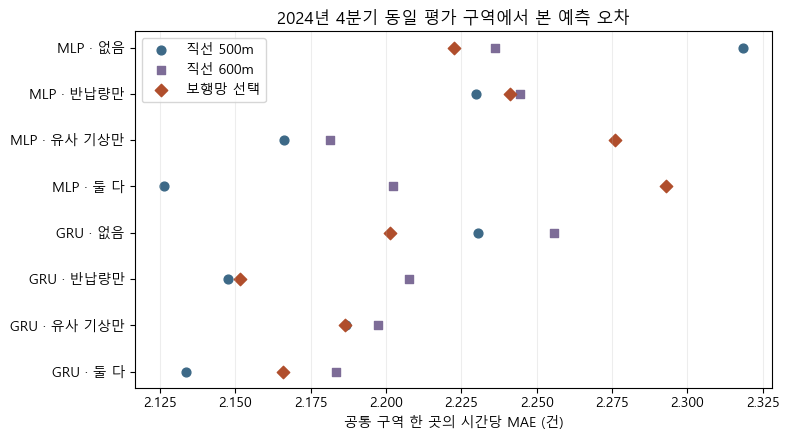

In [5]:
import os
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family":"Malgun Gothic" if os.name=="nt" else "sans-serif"})
summary = fair.pivot(index=["모델","추가 입력"],columns="학습 구획",values="MAE")
summary = summary.loc[[(model,feature) for model in ["MLP","GRU"]
                        for feature in ["없음","반납량만","유사 기상만","둘 다"]]]
y = np.arange(len(summary))
fig,ax = plt.subplots(figsize=(8,4.5))
for name,color,marker in [("직선 500m","#3d6987","o"),("직선 600m","#7d6c97","s"),("보행망 선택","#b04e2c","D")]:
    ax.scatter(summary[name],y,label=name,color=color,marker=marker,s=40)
ax.set(yticks=y,yticklabels=[" · ".join(row) for row in summary.index],
       xlabel="공통 구역 한 곳의 시간당 MAE (건)",title="2024년 4분기 동일 평가 구역에서 본 예측 오차")
ax.invert_yaxis()
ax.grid(axis="x",alpha=.22)
ax.legend()
fig.tight_layout()
plt.show()